# 06 – Bee Haven: Vergleich der Standorte – Honigproduktion

**Ziel:** Für alle Standorte aus `konfiguration/standorte.csv` die Honigproduktion je Saison vergleichbar machen: Gewicht zu Saisonbeginn, Höchstgewicht, Nettozunahme, **Ernte-Ereignisse** und ein **geschätzter Saisonertrag**.

**Warum?** Für die Geschäftsleitung ist die Honigmenge die eigentliche Ergebniszahl: Wie viel bringt ein Standort, wann wird geerntet, und wie unterscheiden sich die Standorte?

**Eingang:** Gold-Tageswerte `gold/<stadt>/tageswerte_<stadt>.parquet` (N4) · **Ausgang:** Tabelle `gold/vergleich/honig_saison.csv` und Grafik `04_images/v1_honig_saison.png`

**Regeln (Annahmen, fachlich zu bestätigen):**
- **Saison** = 1. April bis 30. September (Haupttracht und Ernte in Mitteleuropa).
- **Saisonbeginn** = Median des Gewichts der ersten 7 Tage mit Messwert ab 1. April.
- **Ernte-Ereignis** = Gewichtsverlust von mindestens **3 kg innerhalb von 2 Tagen**, solange der Stock danach noch über 20 kg wiegt (sonst „Waage leer“, schon in N2 ausgeschlossen).
- **Geschätzter Saisonertrag** = Nettozunahme (Höchstgewicht − Saisonbeginn) + Summe der Ernte-Verluste **nach** dem Höchstgewicht. Untergrenze, da Honig, der zwischendurch verbraucht wird, nicht sichtbar ist.
- **Abdeckung** = Anteil der Saisontage mit gültigem Gewicht – unter 80 % gilt die Saison als **unsicher** (z. B. Würzburg 2018: Datenlücke Mai–Oktober).

In [1]:
# --- Parameter ---
ERNTE_KG = 3.0          # Mindestverlust (kg) innerhalb von ERNTE_TAGE, damit ein Abfall als Ernte-Ereignis zählt
ERNTE_TAGE = 2          # Zeitfenster für den Verlust (Tage)
SAISON = ("04-01", "09-30")   # Saison je Jahr (Monat-Tag)
MIN_ABDECKUNG = 0.8     # unter 80 % Tagen mit Gewicht gilt die Saison als unsicher

# --- Bibliotheken ---
import pandas as pd                      # Tabellen
import matplotlib.pyplot as plt          # Grafiken
from pathlib import Path                 # Pfade

# --- Pfade ---
PROJEKT = Path.cwd().parent                                         # Projektordner
LAKE = PROJEKT / "02_daten_ITS-Data" / "lakehouse"                  # lokaler Spiegel des Data Lake
standorte = pd.read_csv(LAKE / "konfiguration" / "standorte.csv")   # alle Standorte
print("Standorte:", list(standorte["stadt"]))

Standorte: ['schwartau', 'wurzburg']


## 1. Tageswerte je Standort laden

In [2]:
# --- Gold-Tageswerte aller Standorte einlesen (Gewicht je Tag, Zeitzone UTC) ---
tage = {}
for _, ort in standorte.iterrows():                                  # je Standort ...
    datei = LAKE / "gold" / ort["stadt"] / f"tageswerte_{ort['stadt']}.parquet"
    if not datei.exists():                                           # ... Standort ohne Gold überspringen
        print("fehlt:", datei.name); continue
    d = pd.read_parquet(datei)[["gewicht_kg", "einflug"]]            # nur benötigte Spalten
    d.index = d.index.tz_convert(None).normalize()                    # Kalendertag ohne Zeitzone
    tage[ort["name"]] = d
    print(f"{ort['name']:15} {len(d):4} Tage, Gewicht an {d['gewicht_kg'].notna().sum()} Tagen")

Bad Schwartau    881 Tage, Gewicht an 812 Tagen
Würzburg         870 Tage, Gewicht an 709 Tagen


**Ergebnis:** siehe Ausgabe – je Standort Anzahl Tage und Tage mit gültigem Gewicht.

## 2. Kennzahlen je Standort und Saison

In [3]:
# --- Kennzahlen je Saison berechnen ---
zeilen = []; ernten = []
for name, d in tage.items():
    for jahr in sorted(d.index.year.unique()):
        von, bis = pd.Timestamp(f"{jahr}-{SAISON[0]}"), pd.Timestamp(f"{jahr}-{SAISON[1]}")
        s = d.loc[von:bis, "gewicht_kg"]                                   # Gewicht in der Saison
        if s.notna().sum() < 14:                                          # zu wenig Daten -> Saison auslassen
            continue
        alle_tage = (bis - von).days + 1
        abdeckung = s.notna().sum() / alle_tage                           # Anteil Tage mit Gewicht
        start = s.dropna().iloc[:7].median()                              # Saisonbeginn (Median erste 7 Tage)
        hoch_tag = s.idxmax(); hoch = s.max()                             # Höchststand und Datum
        verlust = s - s.shift(-ERNTE_TAGE)                                # Verlust bis ERNTE_TAGE später (positiv = Abnahme)
        kandidaten = verlust[(verlust >= ERNTE_KG) & (s.shift(-ERNTE_TAGE) > 20)]
        ereignisse = []                                                    # aufeinanderfolgende Tage zu einem Ereignis zusammenfassen
        for tag, kg in kandidaten.items():
            if ereignisse and (tag - ereignisse[-1][0]).days <= ERNTE_TAGE:
                ereignisse[-1] = (ereignisse[-1][0], max(ereignisse[-1][1], kg))
            else:
                ereignisse.append((tag, kg))
        nach_hoch = [(t, kg) for t, kg in ereignisse if t >= hoch_tag]
        for t, kg in ereignisse:
            ernten.append({"standort": name, "datum": t.date(), "verlust_kg": round(kg, 1), "nach_hoechststand": t >= hoch_tag})
        zeilen.append({"standort": name, "saison": jahr, "abdeckung_%": round(abdeckung * 100),
                       "beginn_kg": round(start, 1), "hoechst_kg": round(hoch, 1), "hoechst_am": hoch_tag.date(),
                       "nettozunahme_kg": round(hoch - start, 1), "ernten": len(nach_hoch),
                       "ernte_kg": round(sum(kg for _, kg in nach_hoch), 1),
                       "saisonertrag_kg": round(hoch - start + sum(kg for _, kg in nach_hoch), 1),
                       "einfluege_mio": round(d.loc[von:bis, "einflug"].sum() / 1e6, 1),
                       "bewertung": "sicher" if abdeckung >= MIN_ABDECKUNG else "unsicher (Datenlücke)"})
saison = pd.DataFrame(zeilen)
saison

,standort,saison,abdeckung_%,beginn_kg,hoechst_kg,hoechst_am,nettozunahme_kg,ernten,ernte_kg,saisonertrag_kg,einfluege_mio,bewertung
0,Bad Schwartau,2017,98,49.3,91.2,2017-06-30,41.9,1,32.1,74.0,13.4,sicher
1,Bad Schwartau,2018,65,48.9,72.0,2018-07-28,23.1,0,0.0,23.1,11.9,unsicher (Datenlücke)
2,Bad Schwartau,2019,33,68.7,79.8,2019-05-20,11.2,0,0.0,11.2,3.1,unsicher (Datenlücke)
3,Würzburg,2017,100,49.4,68.5,2017-06-22,19.1,1,4.6,23.7,6.4,sicher
4,Würzburg,2018,26,50.9,66.8,2018-05-17,15.9,0,0.0,15.9,1.2,unsicher (Datenlücke)
5,Würzburg,2019,27,50.1,56.9,2019-04-25,6.8,0,0.0,6.8,0.6,unsicher (Datenlücke)


**Ergebnis:** eine Zeile je Standort und Saison. Saisons mit Abdeckung unter 80 % sind als „unsicher“ gekennzeichnet und werden nicht verglichen.

In [4]:
# --- Ernte-Ereignisse im Überblick ---
pd.DataFrame(ernten)

,standort,datum,verlust_kg,nach_hoechststand
0,Bad Schwartau,2017-06-04,9.3,False
1,Bad Schwartau,2017-07-24,32.1,True
2,Würzburg,2017-08-29,4.6,True


## 3. Grafik: Gewichtsverlauf der Saison, Standorte nebeneinander

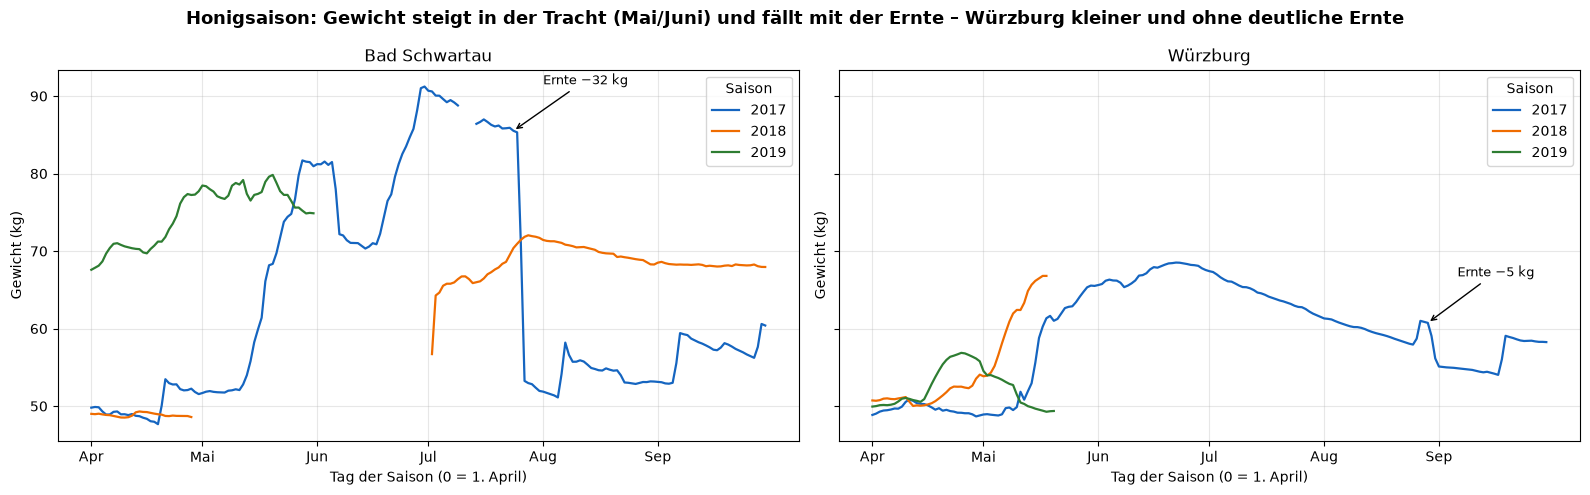

In [5]:
# --- Gewicht je Saisontag, eine Linie je Jahr; Ernte-Ereignisse markiert ---
fig, ax = plt.subplots(1, len(tage), figsize=(8 * len(tage), 5), sharey=True)
ax = ax if len(tage) > 1 else [ax]
fig.suptitle("Honigsaison: Gewicht steigt in der Tracht (Mai/Juni) und fällt mit der Ernte – Würzburg kleiner und ohne deutliche Ernte",
             fontsize=13, fontweight="bold")
farben = {2017: "#1565c0", 2018: "#ef6c00", 2019: "#2e7d32"}
for a, (name, d) in zip(ax, tage.items()):
    for jahr in sorted(d.index.year.unique()):
        s = d.loc[f"{jahr}-{SAISON[0]}":f"{jahr}-{SAISON[1]}", "gewicht_kg"]
        if s.notna().sum() < 14: continue
        x = (s.index - pd.Timestamp(f"{jahr}-{SAISON[0]}")).days           # Tag der Saison
        a.plot(x, s.values, color=farben.get(jahr, "grey"), lw=1.6, label=str(jahr))
    for e in [e for e in ernten if e["standort"] == name and e["nach_hoechststand"]]:
        t = pd.Timestamp(e["datum"]); x = (t - pd.Timestamp(f"{t.year}-{SAISON[0]}")).days
        a.annotate(f"Ernte −{e['verlust_kg']:.0f} kg", xy=(x, d.loc[t, "gewicht_kg"]), xytext=(x + 8, d.loc[t, "gewicht_kg"] + 6),
                   fontsize=9, arrowprops=dict(arrowstyle="->"))
    a.set(title=name, xlabel="Tag der Saison (0 = 1. April)", ylabel="Gewicht (kg)")
    a.set_xticks([0, 30, 61, 91, 122, 153], ["Apr", "Mai", "Jun", "Jul", "Aug", "Sep"])
    a.legend(title="Saison"); a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(PROJEKT / "04_images" / "v1_honig_saison.png", dpi=120, bbox_inches="tight")
plt.show()

**Ergebnis:** siehe Grafik und Fazit unten.

In [6]:
# --- Ergebnis speichern (für Dashboard und Präsentation) ---
ziel = LAKE / "gold" / "vergleich"; ziel.mkdir(parents=True, exist_ok=True)
saison.to_csv(ziel / "honig_saison.csv", index=False)
print("gespeichert:", (ziel / "honig_saison.csv").relative_to(PROJEKT))

gespeichert: 02_daten_ITS-Data/lakehouse/gold/vergleich/honig_saison.csv


## Fazit

**Vergleichbar ist nur die Saison 2017** – nur dort liegt an beiden Standorten an mindestens 80 % der Tage ein gültiges Gewicht vor (2018: Würzburg Datenlücke Mai–Oktober, Schwartau Waage leer 28.04.–02.07.; 2019: Daten enden im Mai).

| Saison 2017 | Bad Schwartau | Würzburg |
| :-- | :-- | :-- |
| Gewicht Saisonbeginn | 49,3 kg | 49,4 kg |
| Höchstgewicht | 91,2 kg (30.06.) | 68,5 kg (22.06.) |
| Nettozunahme in der Tracht | **+41,9 kg** | **+19,1 kg** |
| Ernte-Ereignis nach dem Höchststand | 1 × −32,1 kg (24.07.) | 1 × −4,6 kg (29.08.) |
| **geschätzter Saisonertrag** (Untergrenze) | **ca. 74 kg** | **ca. 24 kg** |
| Einflüge in der Saison | 13,4 Mio. | 6,4 Mio. |

**Deutung:**
- Beide Völker starten mit fast gleichem Gewicht (ca. 49 kg). Schwartau nimmt in der Tracht gut doppelt so viel zu und hat doppelt so viele Einflüge – das stärkere Volk bzw. der ertragreichere Standort.
- Schwartau zeigt eine klare **Honigernte** (−32 kg an einem Tag Ende Juli); der Abfall Anfang Juni (−9 kg vor dem Höchststand) passt eher zu Schwarm oder Teilernte und zählt nicht zum Ertrag.
- Würzburg verliert nach dem Höchststand langsam (Verbrauch), der kleine Abfall Ende August mit anschließendem Anstieg deutet eher auf einen Eingriff (z. B. Fütterung) als auf eine Ernte – **zu prüfen** (kein Imkerei-Protokoll).
- Die Ertragsschätzung ist eine **Untergrenze**: Honig, der zwischendurch verbraucht wird, ist im Gewicht nicht sichtbar.

**Einschränkungen:** keine Angaben der Imkerei zu Ernten, Fütterung oder Völkerstärke; Würzburg-flow (Kursfassung) ohne Stunde 00:00–00:59 ab 2019; Schwellen (3 kg in 2 Tagen) sind Annahmen.

**Für Agenten / ML:** `gold/vergleich/honig_saison.csv` ist die Kennzahlen-Tabelle für Dashboard und Präsentation; Ernte-Erkennung als Regel für Warnhinweise („ungewöhnlicher Gewichtsverlust“) nutzbar.